# Exploration initiale des IRM cérébrales

**Projet :** BrainScanAI - détection semi-supervisée de tumeurs cérébrales  
**Étape :** 1 - Importer et explorer le jeu de données  
**Auteur :** Kilian Lefevre

---

## Objectif du notebook

Avant toute extraction de caractéristiques ou modélisation, ce notebook établit un état des lieux reproductible des données brutes. Il répond aux questions suivantes :

- Combien d'images sont annotées et non annotées ? Les classes annotées sont-elles équilibrées ?
- Les fichiers sont-ils lisibles et homogènes en taille, format et nombre de canaux ?
- Les images semblent-elles visuellement exploitables pour la suite du projet ?

Les données restent **immutables** dans `data/raw/`. Cette étape est strictement descriptive : aucun redimensionnement, aucune normalisation et aucun apprentissage ne sont réalisés ici.

## Contexte des données

Le jeu de données est organisé ainsi :

```text
data/raw/
├── sans_label/             # IRM sans annotation clinique
└── avec_labels/
    ├── cancer/             # IRM annotées « cancer »
    └── normal/             # IRM annotées « normal »
```

Les annotations servent uniquement à décrire le sous-ensemble connu à cette étape. Elles seront réservées plus tard à l'évaluation et à l'apprentissage supervisé/semi-supervisé.

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, UnidentifiedImageError

from brain_mri.config import RAW_DATA_DIR
from brain_mri.dataset import add_file_hash, build_inventory

pd.set_option("display.max_colwidth", 100)
plt.style.use("seaborn-v0_8-whitegrid")

BYTES_PER_KIBIBYTE = 1_024

assert RAW_DATA_DIR.exists(), f"Répertoire introuvable : {RAW_DATA_DIR}"
print(f"Répertoire de données brutes : {RAW_DATA_DIR}")

2026-10-16 11:17:42.444 | INFO     | brain_mri.config:<module>:11 - PROJ_ROOT path is: /Users/kilian/Documents/Repositories/OpenClassrooms/OC-Appliquez-des-approches-semi-supervisees


Répertoire de données brutes : /Users/kilian/Documents/Repositories/OpenClassrooms/OC-Appliquez-des-approches-semi-supervisees/data/raw


## 1. Inventaire des fichiers

`build_inventory` (module `brain_mri.dataset`) crée une table de référence, avec un chemin par image et une étiquette explicite. La valeur manquante de `label` est volontaire : elle représente les images qui ne sont pas annotées par les radiologues.

In [2]:
images = build_inventory(RAW_DATA_DIR)
assert not images.empty, "Aucune image JPEG n'a été trouvée."
assert images["image_id"].is_unique, (
    "Des identifiants de fichier sont dupliqués."
)

images.head()

,image_id,filepath,subset,label,is_labeled,file_size_bytes
0,05340cd4-3bb2-459d-9937-bf27d52d8351,/Users/kilian/Documents/Repositories/OpenClassrooms/OC-Appliquez-des-approches-semi-supervisees/...,cancer,cancer,True,25845
1,0c6f3641-60d9-4a76-abe5-de89d55d5f2c,/Users/kilian/Documents/Repositories/OpenClassrooms/OC-Appliquez-des-approches-semi-supervisees/...,cancer,cancer,True,18082
2,0f718241-8f63-4b55-81ce-315324b51069,/Users/kilian/Documents/Repositories/OpenClassrooms/OC-Appliquez-des-approches-semi-supervisees/...,cancer,cancer,True,18113
3,11a7a426-4806-401e-98b2-b96e7094d1a6,/Users/kilian/Documents/Repositories/OpenClassrooms/OC-Appliquez-des-approches-semi-supervisees/...,cancer,cancer,True,24615
4,1c043dbb-4623-4769-8e5e-0223bd745040,/Users/kilian/Documents/Repositories/OpenClassrooms/OC-Appliquez-des-approches-semi-supervisees/...,cancer,cancer,True,24723


In [3]:
inventory = (
    images.assign(label=images["label"].fillna("non annotée"))
    .groupby(["subset", "label"], dropna=False)
    .size()
    .rename("nombre_images")
    .reset_index()
)

display(inventory)
print(f"Total : {len(images):,} images")
print(f"Images annotées : {images['is_labeled'].sum():,}")
print(f"Images non annotées : {(~images['is_labeled']).sum():,}")

,subset,label,nombre_images
0,cancer,cancer,50
1,normal,normal,50
2,sans_label,non annotée,1406


Total : 1,506 images
Images annotées : 100
Images non annotées : 1,406


### Lecture initiale

Le sous-ensemble annoté doit être équilibré entre `cancer` et `normal` afin de permettre une évaluation comparative plus fiable. Le grand volume d'images non annotées est la motivation de l'approche semi-supervisée : ces données pourront fournir un signal complémentaire après contrôle et labellisation faible.

### Répartition des données

Les deux graphiques distinguent le volume annoté disponible pour l'apprentissage supervisé et la répartition des classes dans ce sous-ensemble. Ils permettent de vérifier visuellement le déséquilibre structurel attendu entre données annotées et non annotées, ainsi que l'équilibre des labels experts.

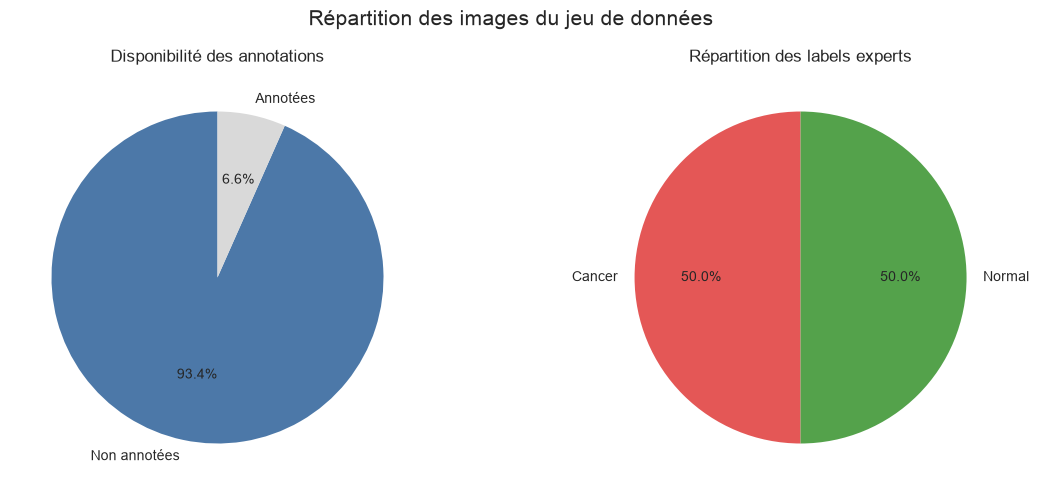

In [4]:
annotation_counts = (
    images["is_labeled"]
    .map({True: "Annotées", False: "Non annotées"})
    .value_counts()
)
label_counts = (
    images.loc[images["is_labeled"], "label"].value_counts().sort_index()
)

figure, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].pie(
    annotation_counts,
    labels=annotation_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4C78A8", "#D9D9D9"],
)
axes[0].set_title("Disponibilité des annotations")

axes[1].pie(
    label_counts,
    labels=label_counts.index.str.capitalize(),
    autopct="%1.1f%%",
    startangle=90,
    colors=["#E45756", "#54A24B"],
)
axes[1].set_title("Répartition des labels experts")

figure.suptitle("Répartition des images du jeu de données", fontsize=15)
plt.tight_layout()
plt.show()

## 2. Contrôle de lisibilité et des propriétés image

Chaque JPEG est ouvert afin de détecter les fichiers corrompus et de relever sa largeur, sa hauteur, son mode couleur et son format. Les erreurs sont conservées dans une table dédiée : le diagnostic reste transparent et réutilisable.

In [5]:
def inspect_image(filepath: Path) -> dict:
    """Retourne les métadonnées d'une image ou une erreur de lecture."""
    try:
        with Image.open(filepath) as image:
            image.load()  # Force la lecture complète du fichier JPEG.
            return {
                "width": image.width,
                "height": image.height,
                "mode": image.mode,
                "format": image.format,
                "read_error": pd.NA,
            }
    except (UnidentifiedImageError, OSError) as error:
        return {
            "width": pd.NA,
            "height": pd.NA,
            "mode": pd.NA,
            "format": pd.NA,
            "read_error": str(error),
        }


metadata = pd.DataFrame([inspect_image(path) for path in images["filepath"]])
images = pd.concat([images, metadata], axis=1)

invalid_images = images.loc[images["read_error"].notna()]
assert invalid_images.empty, (
    f"{len(invalid_images)} image(s) illisible(s) détectée(s)."
)
print(
    f"Contrôle de lecture réussi : {len(images):,} / {len(images):,} images lisibles."
)

Contrôle de lecture réussi : 1,506 / 1,506 images lisibles.


In [6]:
technical_summary = pd.DataFrame(
    {
        "propriété": [
            "formats",
            "modes couleur",
            "dimensions (largeur, hauteur)",
        ],
        "distribution": [
            dict(Counter(images["format"])),
            dict(Counter(images["mode"])),
            dict(Counter(zip(images["width"], images["height"], strict=True))),
        ],
    }
)
display(technical_summary)

assert images[["width", "height"]].nunique().eq(1).all(), (
    "Les dimensions ne sont pas homogènes."
)
print("Les dimensions sont homogènes sur l'ensemble du jeu de données.")

,propriété,distribution
0,formats,{'JPEG': 1506}
1,modes couleur,{'RGB': 1506}
2,"dimensions (largeur, hauteur)","{(512, 512): 1506}"


Les dimensions sont homogènes sur l'ensemble du jeu de données.


### Taille des fichiers

La taille sur disque renseigne sur l'homogénéité de l'encodage JPEG et permet d'anticiper les besoins de stockage et de lecture. Les tailles sont affichées en KiB (kibioctets, 1 KiB = 1 024 octets).

,nombre,minimum,médiane,moyenne,maximum
subset,,,,,
cancer,50,15.8,23.0,22.5,31.8
normal,50,17.4,25.3,29.1,64.3
sans_label,1406,13.1,23.2,24.1,73.7


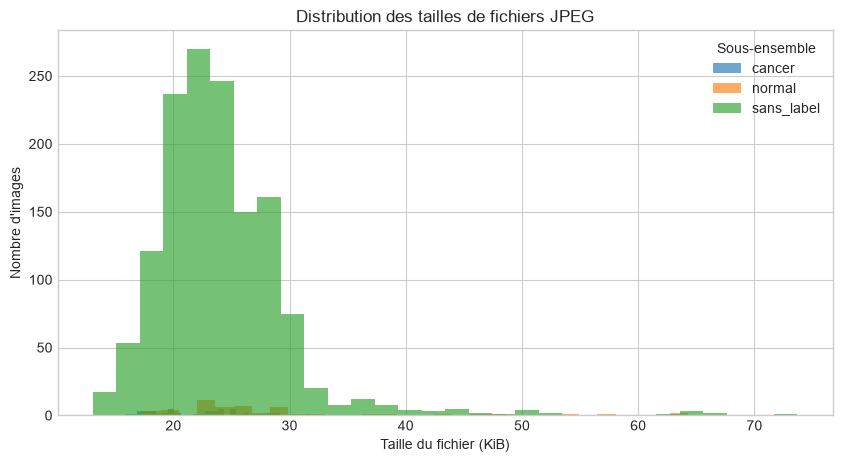

In [7]:
images["file_size_kib"] = images["file_size_bytes"] / BYTES_PER_KIBIBYTE

file_size_summary = (
    images.groupby("subset")["file_size_kib"]
    .agg(
        nombre="count",
        minimum="min",
        médiane="median",
        moyenne="mean",
        maximum="max",
    )
    .round(1)
)
display(file_size_summary)

figure, axis = plt.subplots(figsize=(10, 5))
for subset, group in images.groupby("subset"):
    axis.hist(group["file_size_kib"], bins=30, alpha=0.65, label=subset)
axis.set(
    title="Distribution des tailles de fichiers JPEG",
    xlabel="Taille du fichier (KiB)",
    ylabel="Nombre d'images",
)
axis.legend(title="Sous-ensemble")
plt.show()

## 3. Recherche de doublons exacts

Des fichiers distincts peuvent contenir la même image. Nous calculons une empreinte SHA-256 par fichier pour repérer les doublons binaires exacts. Cette vérification ne détecte pas les images visuellement proches mais encodées différemment ; ce point pourra être approfondi si nécessaire.

In [8]:
images = add_file_hash(images)
exact_duplicates = images.loc[
    images.duplicated("sha256", keep=False)
].sort_values("sha256")
print(
    f"Images impliquées dans un doublon binaire exact : {len(exact_duplicates)}"
)
display(exact_duplicates[["image_id", "subset", "label", "sha256"]].head(10))

Images impliquées dans un doublon binaire exact : 186


,image_id,subset,label,sha256
251,194106ce-8b9a-4a6f-b82d-643f09169c9f,sans_label,NaN,0313adc6f73db38a9acd109fa75480a1da057219f78101d79f7c7b7b839185b8
74,692bfc6f-bcec-42a8-90e9-a867895b9a4b,normal,normal,0313adc6f73db38a9acd109fa75480a1da057219f78101d79f7c7b7b839185b8
994,a8e2d57e-39b3-495c-a585-b2d2d14e0cf3,sans_label,NaN,07116edf0c2621144d9883600ccb4c1ff934333e919373edba711160e362523c
1257,d4e9afda-0833-4af9-ba63-152e615de954,sans_label,NaN,07116edf0c2621144d9883600ccb4c1ff934333e919373edba711160e362523c
1089,b6bc5e43-545c-4ad1-999a-fd8134cd462f,sans_label,NaN,0dbea5d1d90838f50b86de7a1d83d6c5afbd8c5b02706f3139846f29a35f2dd9
886,91babbed-4478-424b-b2fa-65e9aeb3c48a,sans_label,NaN,0dbea5d1d90838f50b86de7a1d83d6c5afbd8c5b02706f3139846f29a35f2dd9
56,2251259e-64fd-44cd-b813-357d0a47e563,normal,normal,155dc182fd94a3df156bb8a8c486d6febeb86d40954b7be535fc159956290002
471,42d9ce05-9a99-4f86-b7fa-807a3f62396b,sans_label,NaN,155dc182fd94a3df156bb8a8c486d6febeb86d40954b7be535fc159956290002
27,a8319ab8-471b-4d18-bb47-a377c4f9bd38,cancer,cancer,1d60c990eacb8c2c4069601eda588149c3b17e4c1e5079119d6429c3d42cdc79
1223,cf0cf298-45f4-4e43-a388-5a0d5f4b6095,sans_label,NaN,1d60c990eacb8c2c4069601eda588149c3b17e4c1e5079119d6429c3d42cdc79


### Inspection visuelle des doublons détectés

Un hash identique indique que deux fichiers sont strictement identiques au niveau binaire. La cellule suivante affiche côte à côte les images de 90 groupes de doublons afin de rendre le constat vérifiable. Le paramètre `n_groups_to_show` permet d'ajuster ce nombre.

> Ces doublons doivent être regroupés avant tout split train/test : une même image ne doit jamais se retrouver à la fois dans l'entraînement et dans le test.

## 4. Exploration visuelle

L'inventaire technique ne suffit pas : une inspection visuelle permet de vérifier que les images correspondent bien à des coupes cérébrales, d'observer le contraste et de repérer d'éventuels artefacts manifestes. Des exemples non annotés sont sélectionnés de façon reproductible, puis les images annotées sont affichées exhaustivement, d'abord pour la classe `cancer`, puis pour la classe `normal`.

> Les vignettes sont un outil de contrôle exploratoire ; elles ne constituent ni un diagnostic médical ni une validation clinique des labels.

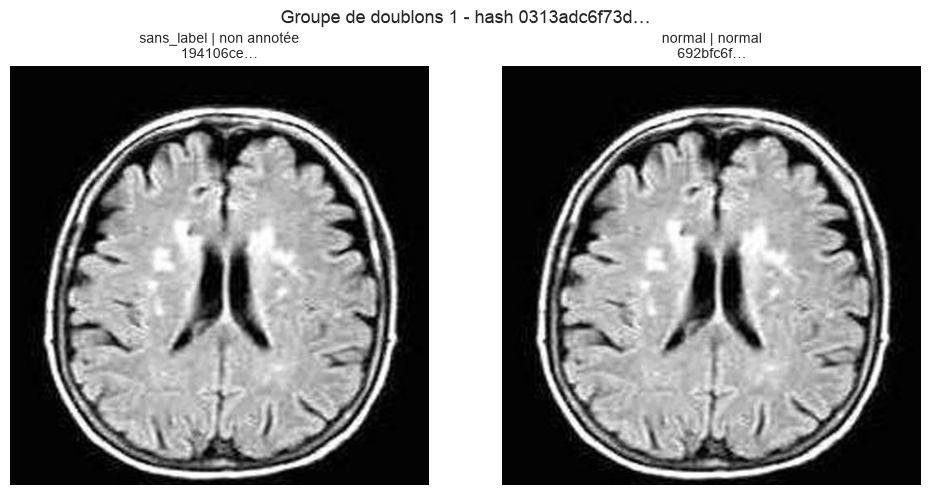

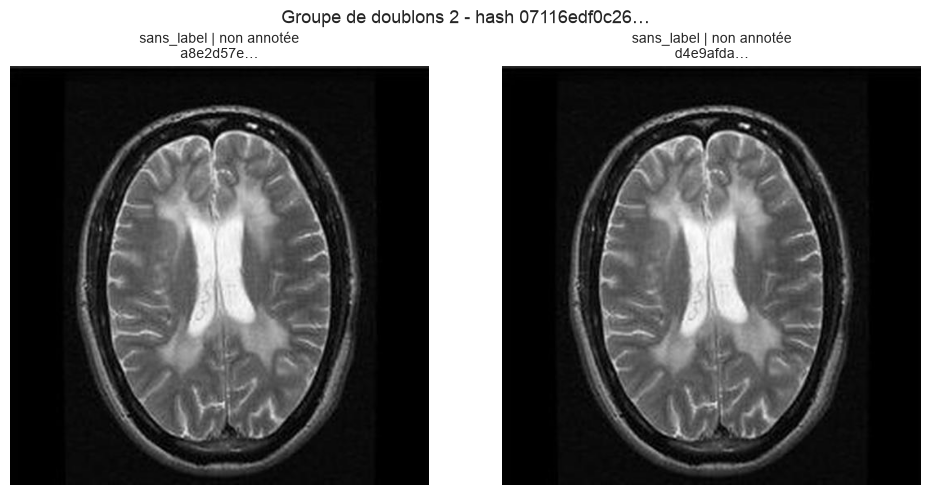

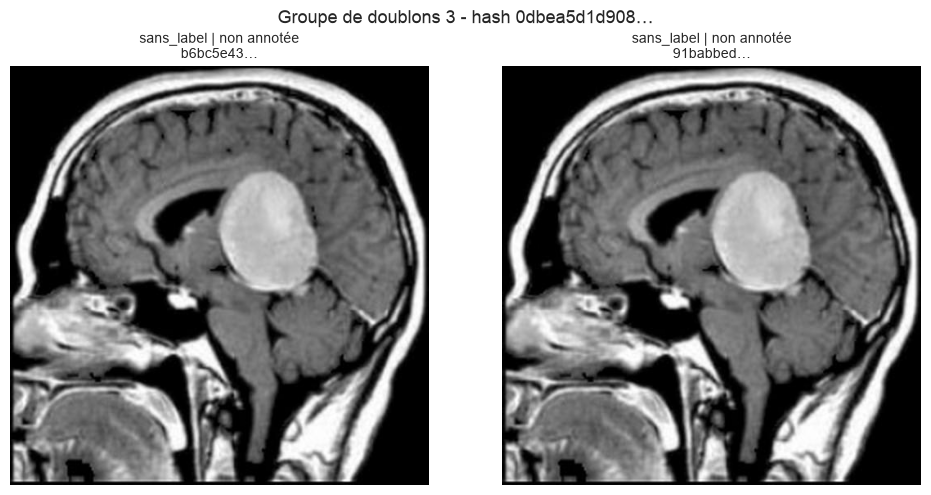

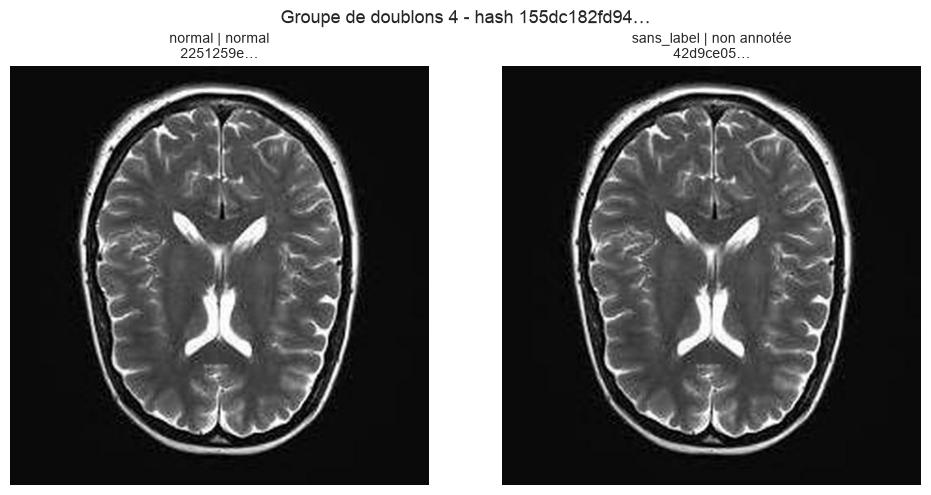

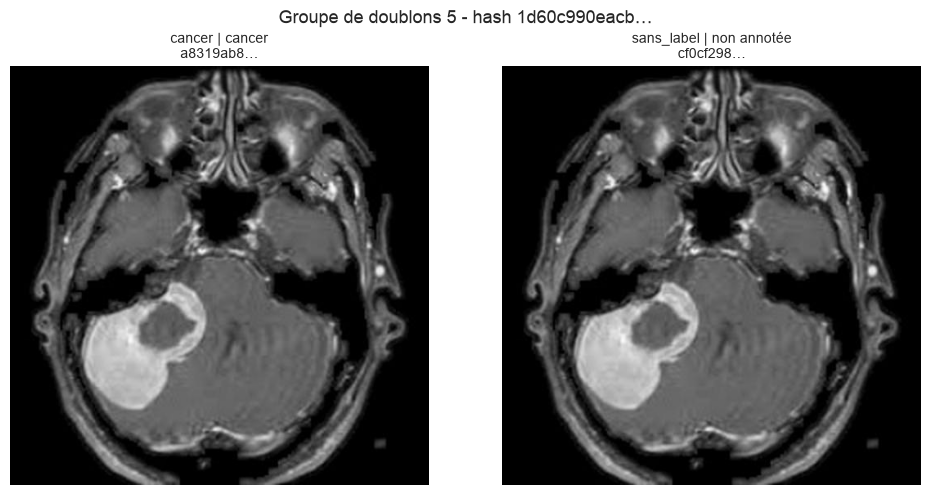

90 groupes de doublons exacts détectés ; 5 affichés.


In [9]:
duplicate_groups = list(exact_duplicates.groupby("sha256", sort=True))
n_groups_to_show = 5

for group_number, (image_hash, group) in enumerate(
    duplicate_groups[:n_groups_to_show], start=1
):
    figure, axes = plt.subplots(
        1, len(group), figsize=(5 * len(group), 5), squeeze=False
    )
    for axis, (_, row) in zip(axes.ravel(), group.iterrows(), strict=True):
        with Image.open(row["filepath"]) as image:
            axis.imshow(image)
        label = row["label"] if pd.notna(row["label"]) else "non annotée"
        axis.set_title(
            f"{row['subset']} | {label}\n{row['image_id'][:8]}…", fontsize=10
        )
        axis.axis("off")
    figure.suptitle(
        f"Groupe de doublons {group_number} - hash {image_hash[:12]}…",
        fontsize=13,
    )
    plt.tight_layout()
    plt.show()

print(
    f"{len(duplicate_groups)} groupes de doublons exacts détectés ; {min(n_groups_to_show, len(duplicate_groups))} affichés."
)

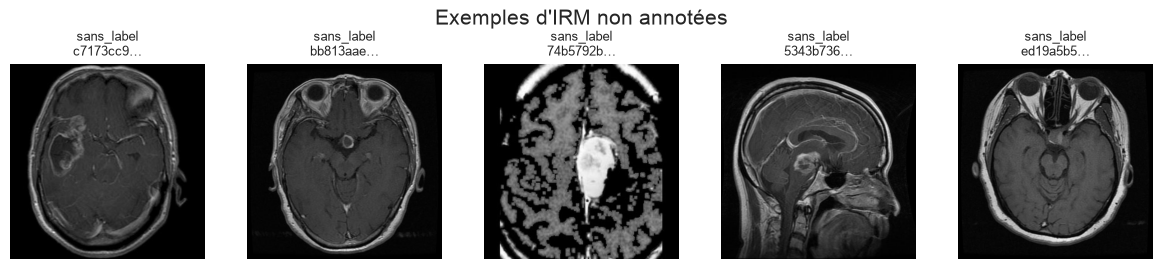

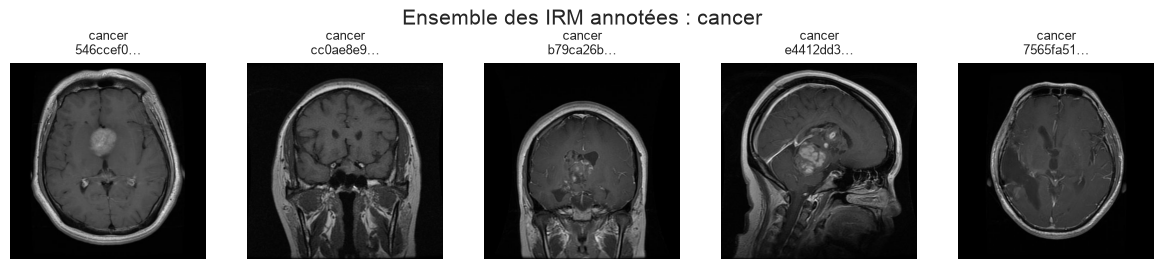

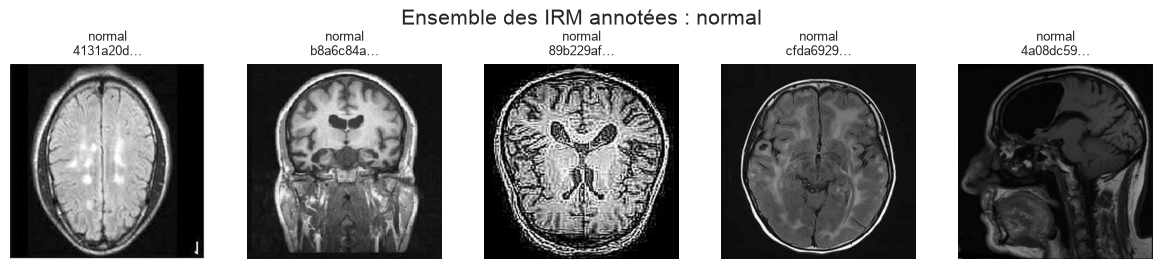

In [10]:
def show_examples(
    frame: pd.DataFrame,
    title: str,
    n_images: int | None = 5,
    n_columns: int = 5,
    random_state: int = 42,
) -> None:
    """Affiche un échantillon ou toutes les IRM d'un sous-ensemble."""
    if n_images is None:
        sample = frame.sort_values(["subset", "image_id"])
    else:
        sample = frame.sample(
            n=min(n_images, len(frame)), random_state=random_state
        )

    n_rows = (len(sample) + n_columns - 1) // n_columns
    figure, axes = plt.subplots(
        n_rows,
        n_columns,
        figsize=(2.4 * n_columns, 2.7 * n_rows),
        squeeze=False,
    )
    for axis, (_, row) in zip(axes.flat, sample.iterrows(), strict=False):
        with Image.open(row["filepath"]) as image:
            axis.imshow(image)
        axis.set_title(f"{row['subset']}\n{row['image_id'][:8]}…", fontsize=9)
        axis.axis("off")
    for axis in axes.flat[len(sample) :]:
        axis.axis("off")
    figure.suptitle(title, fontsize=15, y=0.98)
    plt.tight_layout()
    plt.show()


show_examples(
    images.query("subset == 'sans_label'"), "Exemples d'IRM non annotées"
)
show_examples(
    images.query("label == 'cancer'"),
    "Ensemble des IRM annotées : cancer",
)
show_examples(
    images.query("label == 'normal'"),
    "Ensemble des IRM annotées : normal",
)

## Conclusion de l'étape 1

Les contrôles précédents permettent de décider si le jeu de données est prêt pour la préparation et l'extraction de caractéristiques. La synthèse suivante présente les principaux résultats observés et la décision qui en découle.